In [1]:
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt

In [2]:
simulator = AerSimulator()

shots = 100

print("Qiskit Quantum Coin Bias Experiment")
print("Number of shots:", shots)

Qiskit Quantum Coin Bias Experiment
Number of shots: 100


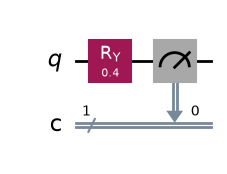

Circuit 1 results: {'0': 96, '1': 4}
Predicted probability of 0: 96.05 %
Predicted probability of 1: 3.95 %


In [3]:
# Create a circuit with exactly one qubit and one classical bit
qc0 = QuantumCircuit(1, 1)

# Apply a small rotation to bias the quantum coin toward 0
qc0.ry(0.4, 0)

# Measure the qubit
qc0.measure(0, 0)

# Display the circuit
display(qc0.draw("mpl"))

# Execute the circuit for 100 shots
job0 = simulator.run(qc0, shots=shots)
result0 = job0.result()

# Get measurement counts
counts0 = result0.get_counts()

print("Circuit 1 results:", counts0)
print("Predicted probability of 0:", round(100 * __import__("math").cos(0.2)**2, 2), "%")
print("Predicted probability of 1:", round(100 * __import__("math").sin(0.2)**2, 2), "%")

# Display histogram
plot_histogram(counts0, title="Circuit 1: 0 Occurs More Frequently")
plt.show()

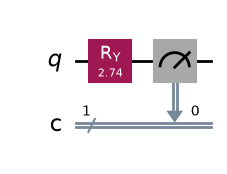

Circuit 2 results: {'1': 91, '0': 9}
Predicted probability of 0: 3.95 %
Predicted probability of 1: 96.05 %


In [4]:
import math

# Create a circuit with exactly one qubit and one classical bit
qc1 = QuantumCircuit(1, 1)

# Rotate the qubit to make outcome 1 more likely
qc1.ry(math.pi - 0.4, 0)

# Measure the qubit
qc1.measure(0, 0)

# Display the circuit
display(qc1.draw("mpl"))

# Execute the circuit for 100 shots
job1 = simulator.run(qc1, shots=shots)
result1 = job1.result()

# Get measurement counts
counts1 = result1.get_counts()

print("Circuit 2 results:", counts1)
print("Predicted probability of 0:", round(100 * math.sin(0.2)**2, 2), "%")
print("Predicted probability of 1:", round(100 * math.cos(0.2)**2, 2), "%")

# Display histogram
plot_histogram(counts1, title="Circuit 2: 1 Occurs More Frequently")
plt.show()

In [5]:
print("CIRCUIT 1: 0 IS MORE LIKELY")
print(counts0)

print("\nCIRCUIT 2: 1 IS MORE LIKELY")
print(counts1)

# Display both histograms together
plot_histogram(
    [counts0, counts1],
    legend=["Circuit 1: Bias toward 0", "Circuit 2: Bias toward 1"],
    title="Comparison of Biased Quantum Coins"
)

plt.show()

CIRCUIT 1: 0 IS MORE LIKELY
{'0': 96, '1': 4}

CIRCUIT 2: 1 IS MORE LIKELY
{'1': 91, '0': 9}


In [6]:
def display_percentages(counts):
    total = sum(counts.values())

    zeros = counts.get("0", 0)
    ones = counts.get("1", 0)

    print("Total shots:", total)
    print("Number of 0 outcomes:", zeros)
    print("Number of 1 outcomes:", ones)
    print("Percentage of 0:", round(zeros / total * 100, 2), "%")
    print("Percentage of 1:", round(ones / total * 100, 2), "%")


print("Circuit 1:")
display_percentages(counts0)

print("\nCircuit 2:")
display_percentages(counts1)

Circuit 1:
Total shots: 100
Number of 0 outcomes: 96
Number of 1 outcomes: 4
Percentage of 0: 96.0 %
Percentage of 1: 4.0 %

Circuit 2:
Total shots: 100
Number of 0 outcomes: 9
Number of 1 outcomes: 91
Percentage of 0: 9.0 %
Percentage of 1: 91.0 %


In [7]:
print("Circuit 1:")
print("Number of qubits:", qc0.num_qubits)
print("Number of classical bits:", qc0.num_clbits)
print("Number of gates before measurement:", qc0.size() - 1)

print("\nCircuit 2:")
print("Number of qubits:", qc1.num_qubits)
print("Number of classical bits:", qc1.num_clbits)
print("Number of gates before measurement:", qc1.size() - 1)

print("\nShots per circuit:", shots)
print("Both circuits include measurement.")
print("Challenge 2 completed!")

Circuit 1:
Number of qubits: 1
Number of classical bits: 1
Number of gates before measurement: 1

Circuit 2:
Number of qubits: 1
Number of classical bits: 1
Number of gates before measurement: 1

Shots per circuit: 100
Both circuits include measurement.
Challenge 2 completed!
